# 03 – Race analysis

In this notebook I answer the questions of the project one block at a time, using the cleaned laps from notebook 02. Each section loads a snapshot, calls functions of the package (`f1_telemetry.cleaning`, `f1_telemetry.analysis`, `f1_telemetry.visualization`) and shows the result. No analysis logic lives here.

In [ ]:
%load_ext autoreload
%autoreload 2

In [1]:
import sys
from pathlib import Path

# The kernel may start in notebooks/ or in the project root: look upwards
# for pyproject.toml, which only exists in the root.
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)

# Let Python find the package, which lives in src/ (no pip install needed)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

## Race and data

I choose the race with two constants. The data comes from the CSV snapshot, so the notebook runs without internet. Before anything else I check whether the race was wet: pace on a track that dries out or floods is not comparable lap by lap, so the pace analysis below only makes sense for a dry race.

In [2]:
from f1_telemetry.analysis import driver_pace
from f1_telemetry.cleaning import get_clean_laps, is_wet_race, prepare_laps
from f1_telemetry.data_loader import (
    LAP_DATETIME_COLUMNS,
    LAP_TIMEDELTA_COLUMNS,
    load_dataframe,
    snapshot_path,
)
from f1_telemetry.visualization import plot_pace_distribution

YEAR = 2022
ROUND = 1
RACE_NAME = "Bahrain"

raw_laps = load_dataframe(
    snapshot_path(YEAR, ROUND, "R", "laps"),
    timedelta_columns=LAP_TIMEDELTA_COLUMNS,
    datetime_columns=LAP_DATETIME_COLUMNS,
)
laps = prepare_laps(raw_laps)
print(RACE_NAME, YEAR, "| laps:", len(laps), "| wet race:", is_wet_race(laps))

Bahrain 2022 | laps: 1125 | wet race: False


## B1 – Race pace

For each driver I take the median of the clean laps (no first lap, in or out lap, safety car or yellow flag, deleted lap). I use the median because a single odd lap hardly moves it. `CleanLaps` shows how many laps each number is based on, `StdTime` shows how consistent the driver was, and `GapToBest` is the distance in seconds from the driver with the fastest median. Drivers with fewer than 5 clean laps would be left out.

In [3]:
pace = driver_pace(laps)
pace.round(3)

,Driver,Team,CleanLaps,MedianTime,MeanTime,StdTime,FastestTime,GapToBest
0,LEC,Ferrari,46,97.693,97.599,1.295,94.570,0.000
1,PER,Red Bull Racing,42,98.058,98.061,1.278,96.089,0.365
2,VER,Red Bull Racing,41,98.091,97.847,1.177,95.440,0.398
3,SAI,Ferrari,44,98.150,98.018,1.285,95.740,0.457
4,HAM,Mercedes,42,98.380,98.303,1.182,96.228,0.688
5,RUS,Mercedes,44,98.822,98.627,1.195,96.302,1.129
6,TSU,AlphaTauri,42,99.040,99.354,1.248,97.104,1.347
7,MAG,Haas F1 Team,45,99.058,99.092,1.438,96.623,1.365
8,OCO,Alpine,43,99.188,99.290,1.176,97.110,1.495
9,GAS,AlphaTauri,39,99.513,99.528,1.018,97.324,1.820


The boxplot below shows all clean laps of each driver, ordered from the fastest median on the left. The height of a box is the consistency: a short box means similar lap times all race long.

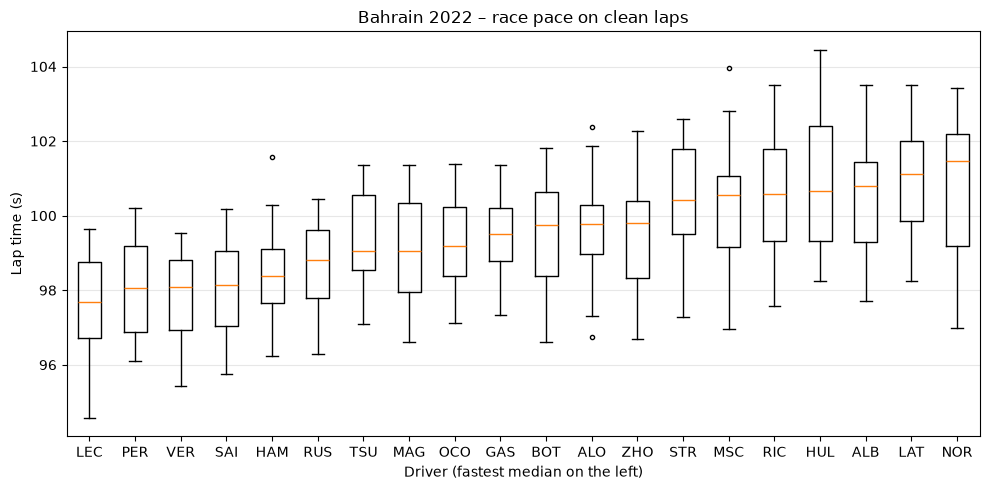

In [4]:
clean = get_clean_laps(laps)
fig = plot_pace_distribution(
    clean, pace, title=f"{RACE_NAME} {YEAR} – race pace on clean laps"
)

Race pace is not the finishing order. As a quick look, I put the pace rank next to the grid and finishing positions from the results snapshot. Differences can come from the grid, strategy, safety cars or retirements; the next blocks and the grid-versus-finish analysis look at those.

In [5]:
results = load_dataframe(snapshot_path(YEAR, ROUND, "R", "results"))
compare = (
    pace[["Driver", "Team", "MedianTime"]]
    .merge(
        results[["Abbreviation", "GridPosition", "Position"]],
        left_on="Driver",
        right_on="Abbreviation",
        how="left",
    )
    .drop(columns="Abbreviation")
)
compare.insert(0, "PaceRank", compare.index + 1)
compare.round(3)

,PaceRank,Driver,Team,MedianTime,GridPosition,Position
0,1,LEC,Ferrari,97.693,1.0,1.0
1,2,PER,Red Bull Racing,98.058,4.0,18.0
2,3,VER,Red Bull Racing,98.091,2.0,19.0
3,4,SAI,Ferrari,98.150,3.0,2.0
4,5,HAM,Mercedes,98.380,5.0,3.0
5,6,RUS,Mercedes,98.822,9.0,4.0
6,7,TSU,AlphaTauri,99.040,16.0,8.0
7,8,MAG,Haas F1 Team,99.058,7.0,5.0
8,9,OCO,Alpine,99.188,11.0,7.0
9,10,GAS,AlphaTauri,99.513,10.0,20.0
